### Including the implementation of `tanh()` in out class

In [26]:
import math
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [27]:
# Build the Value Object
# And include the definition of tanh()
class Value:
    def __init__(self, data, _children=(), _op='', label=''):
        self.data = data
        self.grad = 0.0
        self._prev = set(_children)
        self._op = _op
        self.label = label

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        out = Value(self.data + other.data, (self, other), '+')
        return out

    def __mul__(self, other):
        out = Value(self.data * other.data, (self, other), '*')
        return out

    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1) / (math.exp(2*x) + 1) 
        out = Value(t, (self, ), "tanh")
        return out

In [28]:
from graphviz import Digraph


def trace(root):
    # builds a set of all nodes and edges in a graph
    nodes, edges = set(), set()

    def build(v):
        if v not in nodes:
            nodes.add(v)

            for child in v._prev:
                edges.add((child, v))
                build(child)

    build(root)
    print(nodes)
    print(edges)
    return nodes, edges


def draw_dot(root):
    dot = Digraph(format="svg", graph_attr={"rankdir": "LR"}) # LR = Left to right 

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))

        # for any value in the graph, create a rectangular (`record`) node for it
        dot.node(name=uid, label="{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape="record")

        if n._op:
            # if this value is a result of some operation, create an op node for it
            dot.node(name=uid + n._op, label = n._op)
            # and connect this node to it
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        # Connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

### Applying the above backpropagation technique to a real neuron as shown below

In [29]:
# inputs, x1 and x2
x1 = Value(2.0, label="x1")
x2 = Value(0.0, label="x2")

# weights (synaptic strengths of each input)
w1 = Value(-3.0, label="w1")
w2 = Value(1.0, label="w2")

# bias of the neuron
# b = Value(8.0, label="b")
b = Value(6.8813735870195432, label="b")

# In the below, `y` is what we are trying to implement
# y = x1w1 + x2w2 + b
x1w1 = x1*w1
x1w1.label = "x1*w1"

x2w2 = x2*w2
x2w2.label = "x2*w2"

x1w1x2w2 = x1w1 + x2w2
x1w1x2w2.label = "x1w1 + x2w2"

# `n` is the weighted sum without the activation function applied
n = x1w1x2w2 + b
n.label = "n"

# Output
o = n.tanh()
o.label = "o"

{Value(data=0.8813735870195432), Value(data=0.0), Value(data=0.0), Value(data=-6.0), Value(data=0.7071067811865476), Value(data=2.0), Value(data=-3.0), Value(data=6.881373587019543), Value(data=1.0), Value(data=-6.0)}
{(Value(data=-3.0), Value(data=-6.0)), (Value(data=0.8813735870195432), Value(data=0.7071067811865476)), (Value(data=6.881373587019543), Value(data=0.8813735870195432)), (Value(data=1.0), Value(data=0.0)), (Value(data=2.0), Value(data=-6.0)), (Value(data=0.0), Value(data=0.0)), (Value(data=-6.0), Value(data=-6.0)), (Value(data=0.0), Value(data=-6.0)), (Value(data=-6.0), Value(data=0.8813735870195432))}


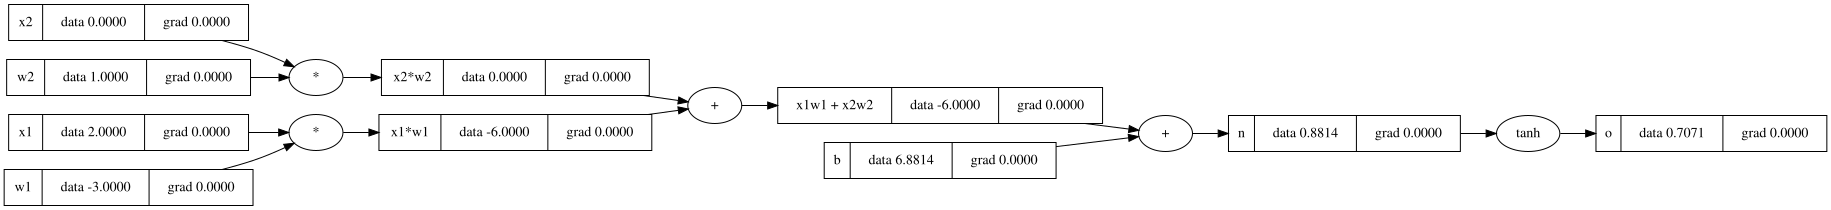

In [30]:
draw_dot(o)

### Backpropagation

{Value(data=0.8813735870195432), Value(data=0.0), Value(data=0.0), Value(data=-6.0), Value(data=0.7071067811865476), Value(data=2.0), Value(data=-3.0), Value(data=6.881373587019543), Value(data=1.0), Value(data=-6.0)}
{(Value(data=-3.0), Value(data=-6.0)), (Value(data=0.8813735870195432), Value(data=0.7071067811865476)), (Value(data=6.881373587019543), Value(data=0.8813735870195432)), (Value(data=1.0), Value(data=0.0)), (Value(data=2.0), Value(data=-6.0)), (Value(data=0.0), Value(data=0.0)), (Value(data=-6.0), Value(data=-6.0)), (Value(data=0.0), Value(data=-6.0)), (Value(data=-6.0), Value(data=0.8813735870195432))}


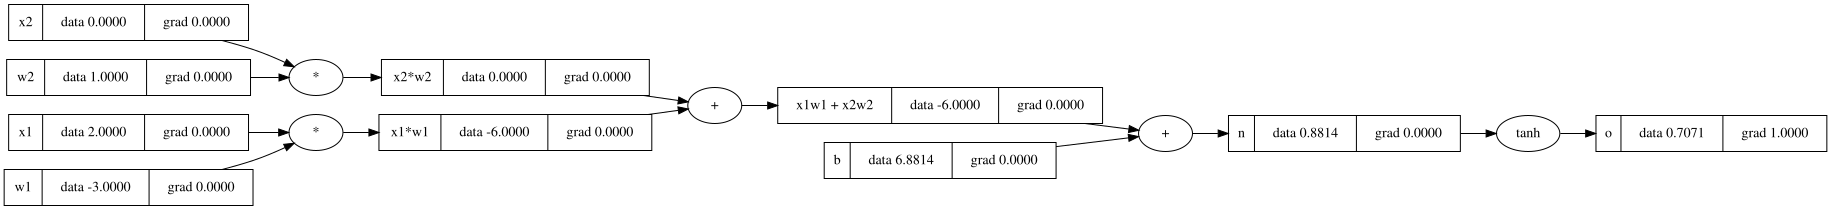

In [31]:
# The derivative of the output (o) with respect to `o` is just 1.0
# Therefore 
o.grad = 1.0
draw_dot(o)

In [32]:
# Derivative of `o` w.r.t tanh(n)

# do/dn = 1 - tanh^2(n)
# But tanh(n) = o

# Therefore do/dn = 1 - o^2

In [33]:
1 - o.data**2

0.4999999999999999

{Value(data=0.8813735870195432), Value(data=0.0), Value(data=0.0), Value(data=-6.0), Value(data=0.7071067811865476), Value(data=2.0), Value(data=-3.0), Value(data=6.881373587019543), Value(data=1.0), Value(data=-6.0)}
{(Value(data=-3.0), Value(data=-6.0)), (Value(data=0.8813735870195432), Value(data=0.7071067811865476)), (Value(data=6.881373587019543), Value(data=0.8813735870195432)), (Value(data=1.0), Value(data=0.0)), (Value(data=2.0), Value(data=-6.0)), (Value(data=0.0), Value(data=0.0)), (Value(data=-6.0), Value(data=-6.0)), (Value(data=0.0), Value(data=-6.0)), (Value(data=-6.0), Value(data=0.8813735870195432))}


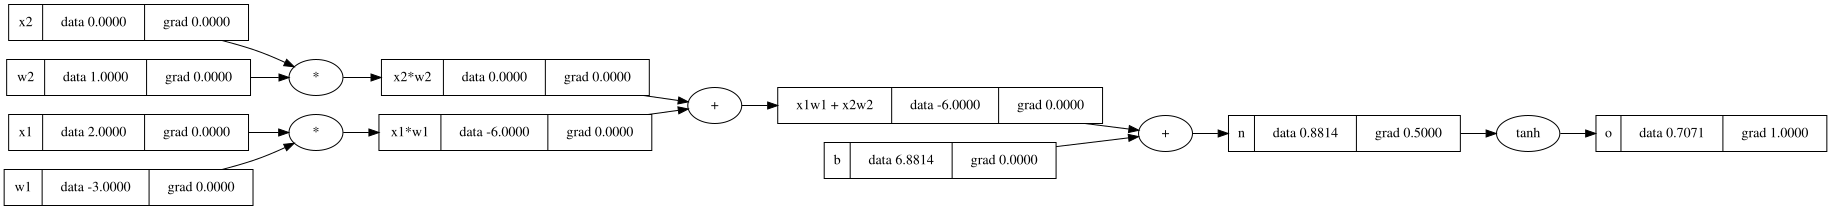

In [34]:
# Therefore, n.grad is given below
n.grad = 0.5
draw_dot(o)

In [35]:
# Note, when you encounter a plus node.
# The gradient just flows backward to all nodes connected to it.
# Hence, in the above; n.grad = 0.500 flows backward to  the two nodes connected to it.

{Value(data=0.8813735870195432), Value(data=0.0), Value(data=0.0), Value(data=-6.0), Value(data=0.7071067811865476), Value(data=2.0), Value(data=-3.0), Value(data=6.881373587019543), Value(data=1.0), Value(data=-6.0)}
{(Value(data=-3.0), Value(data=-6.0)), (Value(data=0.8813735870195432), Value(data=0.7071067811865476)), (Value(data=6.881373587019543), Value(data=0.8813735870195432)), (Value(data=1.0), Value(data=0.0)), (Value(data=2.0), Value(data=-6.0)), (Value(data=0.0), Value(data=0.0)), (Value(data=-6.0), Value(data=-6.0)), (Value(data=0.0), Value(data=-6.0)), (Value(data=-6.0), Value(data=0.8813735870195432))}


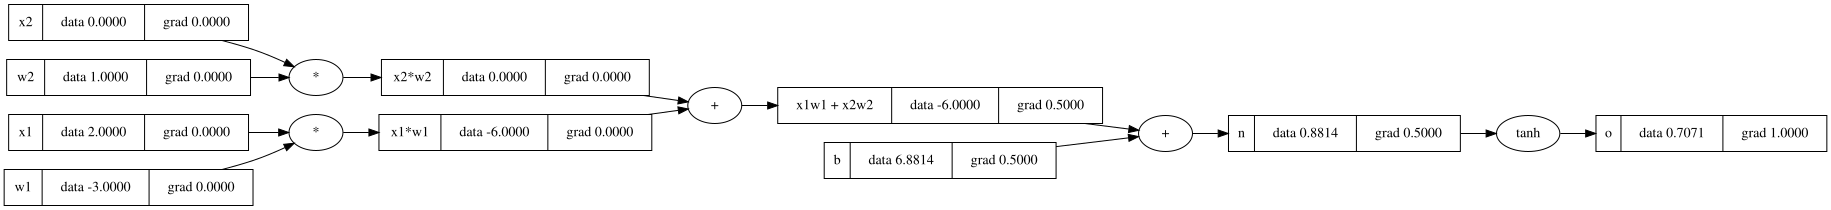

In [36]:
# Therefore
x1w1x2w2.grad = 0.5
b.grad = 0.5
draw_dot(o)

{Value(data=0.8813735870195432), Value(data=0.0), Value(data=0.0), Value(data=-6.0), Value(data=0.7071067811865476), Value(data=2.0), Value(data=-3.0), Value(data=6.881373587019543), Value(data=1.0), Value(data=-6.0)}
{(Value(data=-3.0), Value(data=-6.0)), (Value(data=0.8813735870195432), Value(data=0.7071067811865476)), (Value(data=6.881373587019543), Value(data=0.8813735870195432)), (Value(data=1.0), Value(data=0.0)), (Value(data=2.0), Value(data=-6.0)), (Value(data=0.0), Value(data=0.0)), (Value(data=-6.0), Value(data=-6.0)), (Value(data=0.0), Value(data=-6.0)), (Value(data=-6.0), Value(data=0.8813735870195432))}


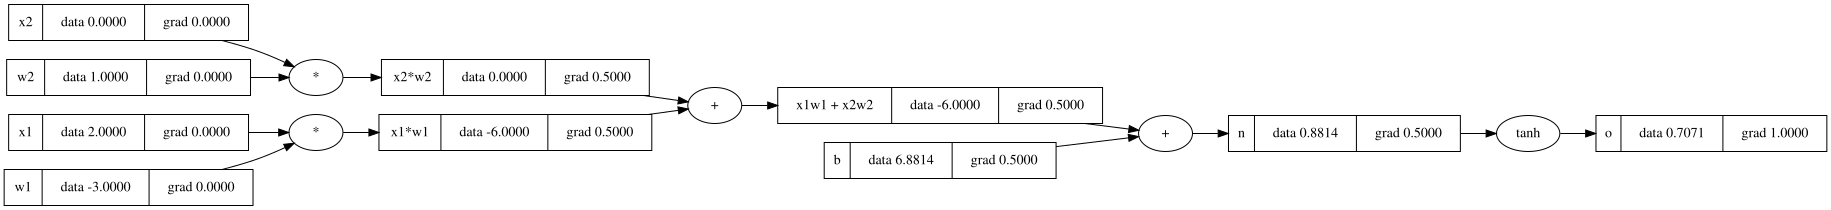

In [37]:
# Same logic as the above applies to the next node.
# Applying backpropagation

x1w1.grad = 0.5
x2w2.grad = 0.5

draw_dot(o)

In [38]:
# Backpropagation for x2 * w2
#Note: Check Karpathy (page 13 and 14) on study papers

x2.grad = w2.data * x2w2.grad
w2.grad = x2.data * x2w2.grad

print("x2.grad:", x2.grad)
print("w2.grad:", w2.grad)

x2.grad: 0.5
w2.grad: 0.0


{Value(data=0.8813735870195432), Value(data=0.0), Value(data=0.0), Value(data=-6.0), Value(data=0.7071067811865476), Value(data=2.0), Value(data=-3.0), Value(data=6.881373587019543), Value(data=1.0), Value(data=-6.0)}
{(Value(data=-3.0), Value(data=-6.0)), (Value(data=0.8813735870195432), Value(data=0.7071067811865476)), (Value(data=6.881373587019543), Value(data=0.8813735870195432)), (Value(data=1.0), Value(data=0.0)), (Value(data=2.0), Value(data=-6.0)), (Value(data=0.0), Value(data=0.0)), (Value(data=-6.0), Value(data=-6.0)), (Value(data=0.0), Value(data=-6.0)), (Value(data=-6.0), Value(data=0.8813735870195432))}


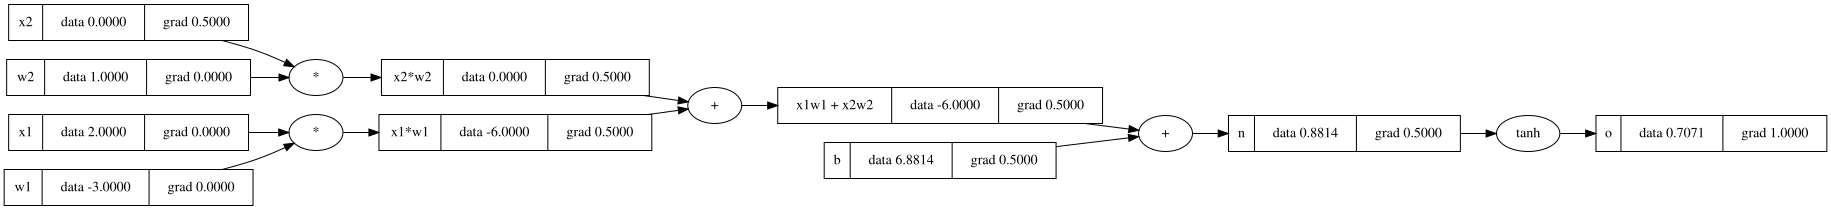

In [39]:
draw_dot(o)

In [40]:
# Backpropagation for x1 * w1

x1.grad = w1.data * x1w1.grad
w1.grad = x1.data * x1w1.grad

print("x1.grad:", x1.grad)
print("w1.grad:", w1.grad)

x1.grad: -1.5
w1.grad: 1.0


{Value(data=0.8813735870195432), Value(data=0.0), Value(data=0.0), Value(data=-6.0), Value(data=0.7071067811865476), Value(data=2.0), Value(data=-3.0), Value(data=6.881373587019543), Value(data=1.0), Value(data=-6.0)}
{(Value(data=-3.0), Value(data=-6.0)), (Value(data=0.8813735870195432), Value(data=0.7071067811865476)), (Value(data=6.881373587019543), Value(data=0.8813735870195432)), (Value(data=1.0), Value(data=0.0)), (Value(data=2.0), Value(data=-6.0)), (Value(data=0.0), Value(data=0.0)), (Value(data=-6.0), Value(data=-6.0)), (Value(data=0.0), Value(data=-6.0)), (Value(data=-6.0), Value(data=0.8813735870195432))}


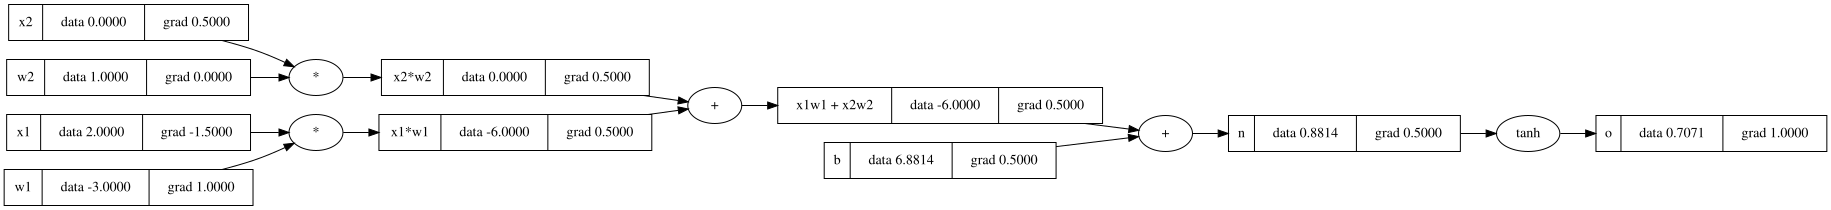

In [41]:
draw_dot(o)